# Phase 3B Step 11 — Multicollinearity Analysis

## Customer Retention Intelligence System

This independent notebook performs minimum-sufficient multicollinearity diagnostics on the configured development split. It reuses the feature definitions and structural relationships documented in Notebooks 05, 10, 13, and 14 without regenerating correlation matrices or statistical tests. All encoding, scaling, and auxiliary regression objects are temporary and notebook-local. No feature is permanently transformed, removed, or selected, and no churn model is trained.

## 1. Independent, leakage-safe setup

The project root is detected from marker files and configuration is loaded through the existing utility. The only data read is the configured `data/processed/development.parquet`; held-out test and complete validated data are never loaded.

In [1]:
# ruff: noqa: E501
import hashlib
import importlib.metadata as metadata
import sys
from pathlib import Path


def find_project_root(start: Path) -> Path:
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "params.yaml").is_file():
            return candidate
    raise FileNotFoundError("Could not locate project root.")


PROJECT_ROOT = find_project_root(Path.cwd())
SRC_PATH = PROJECT_ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

from retention.utils.config import load_config  # noqa: E402

config = load_config(PROJECT_ROOT / "params.yaml")
configured_development_path = Path(config["data"]["development_path"])
assert configured_development_path == Path("data/processed/development.parquet")
development_path = (PROJECT_ROOT / configured_development_path).resolve()
assert development_path.is_file()

print(f"Project root: {PROJECT_ROOT}")
print(f"Input: {configured_development_path}")
print(f"Python: {sys.version.split()[0]} ({sys.executable})")
for package in ["pandas", "numpy", "matplotlib", "pyarrow"]:
    print(f"{package}: {metadata.version(package)}")

Project root: /Users/harshagarwal/Projects/ChurnRatePredictor
Input: data/processed/development.parquet
Python: 3.11.14 (/Users/harshagarwal/Projects/ChurnRatePredictor/.venv/bin/python)
pandas: 2.3.3
numpy: 2.4.6
matplotlib: 3.11.2
pyarrow: 26.0.1


In [2]:
# ruff: noqa: E501
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.float_format", lambda value: f"{value:,.8g}")
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.labelsize": 11})

random_state = int(config["project"]["random_state"])
target_column = config["data"]["target_column"]
identifier_column = config["data"]["id_column"]
source_sha256_before = hashlib.sha256(development_path.read_bytes()).hexdigest()
df = pd.read_parquet(development_path)
numerical_features = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_features = ["gender", "SeniorCitizen", "Partner", "Dependents", "PhoneService", "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling", "PaymentMethod"]
predictor_features = numerical_features + categorical_features

assert df.shape == (5_634, 21)
assert set(df[target_column].unique()) == {"No", "Yes"}
assert identifier_column not in predictor_features and target_column not in predictor_features
assert df[predictor_features].notna().all().all()
print(f"Development data: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Random state preserved: {random_state}")
print(f"Development SHA-256: {source_sha256_before}")

Development data: 5,634 rows × 21 columns
Random state preserved: 42
Development SHA-256: 28d12b92122ab94a8172be83e2bcf7e93b128a1bf3633c2b48075c426864da13


## 2. Statistical fundamentals

**Multicollinearity** is linear dependence among predictors. With **perfect multicollinearity**, one design column is an exact linear combination of others, the design matrix is rank deficient, and ordinary least-squares coefficients are not uniquely identifiable. **Approximate multicollinearity** means the combination is only close; coefficients remain identifiable but can become unstable.

Pairwise correlation examines two variables at a time. Multicollinearity can involve one predictor being explained by several others even when no single pair is extreme. This is why pairwise matrices from Notebook 05 and VIF answer related but different questions.

The **dummy-variable trap** occurs when all categories of a feature plus an intercept are included. Dropping one reference category removes that within-feature identity, but it does not remove dependencies *between* features. Here, service-status labels inherit states such as `No phone service` and `No internet service`, creating structural dependencies across separately encoded variables. Structural dependence follows the product definition; it is not necessarily a data-quality error.

In unregularized linear or logistic regression, collinearity can inflate coefficient variance and standard errors, make signs and magnitudes sensitive to small data changes, and weaken individual-coefficient interpretation. Prediction can remain accurate because many coefficient combinations produce similar fitted values. Tree models do not require an invertible design and usually retain predictive performance, although importance can be split or become unstable across correlated variables. Neural networks can also predict with redundant inputs, but optimization, parameter identifiability, and attribution may become less stable; regularization and scaling can help. Thus coefficient stability and predictive accuracy are distinct objectives.

## 3. VIF definition and safe implementation

For predictor $X_j$, an auxiliary linear regression with an intercept predicts it from all other design columns. If its coefficient of determination is $R_j^2$,

$$VIF_j=\frac{1}{1-R_j^2},\qquad Tolerance_j=\frac{1}{VIF_j}=1-R_j^2.
$$

VIF quantifies variance inflation for a coefficient under the specified design coding. Values above 5 or 10 are common screening heuristics, not universal removal rules. Exact dependence gives $R^2=1$, infinite VIF, and zero tolerance. Constant columns have no outcome variance and are explicitly labelled rather than assigned a misleading finite VIF. The implementation uses an intercept and `numpy.linalg.lstsq`; a residual-to-total sum-of-squares ratio at machine-scale tolerance is treated as exact dependence.

In [3]:
# ruff: noqa: E501
def calculate_vif(design: pd.DataFrame, exact_tolerance: float = 1e-12) -> pd.DataFrame:
    values = design.to_numpy(dtype=float)
    if not np.isfinite(values).all():
        raise ValueError("VIF design must contain only finite values.")
    rows = []
    for column_index, column in enumerate(design.columns):
        outcome = values[:, column_index]
        centered_total = np.sum((outcome - outcome.mean()) ** 2)
        if centered_total <= np.finfo(float).eps * max(1.0, np.sum(outcome**2)):
            rows.append({"predictor": column, "auxiliary_r_squared": np.nan, "vif": np.inf, "tolerance": 0.0, "status": "Constant predictor"})
            continue
        other_predictors = np.delete(values, column_index, axis=1)
        auxiliary_design = np.column_stack([np.ones(len(outcome)), other_predictors])
        coefficients = np.linalg.lstsq(auxiliary_design, outcome, rcond=None)[0]
        residual_sum_squares = np.sum((outcome - auxiliary_design @ coefficients) ** 2)
        residual_ratio = max(0.0, residual_sum_squares / centered_total)
        if residual_ratio <= exact_tolerance:
            r_squared, vif, tolerance = 1.0, np.inf, 0.0
            status = "Exact linear dependency"
        else:
            r_squared = float(np.clip(1.0 - residual_ratio, 0.0, 1.0))
            tolerance = 1.0 - r_squared
            vif = 1.0 / tolerance
            status = "Finite"
        rows.append({"predictor": column, "auxiliary_r_squared": r_squared, "vif": vif, "tolerance": tolerance, "status": status})
    return pd.DataFrame(rows)


def diagnostic_interpretation(vif: float) -> str:
    if not np.isfinite(vif):
        return "Exact dependency; coefficient is not separately identifiable"
    if vif >= 10:
        return "High finite inflation under this coding; investigate stability"
    if vif >= 5:
        return "Elevated finite inflation; review with domain context"
    return "Below common screening thresholds"


def scaled_matrix_diagnostics(design: pd.DataFrame) -> dict:
    values = design.to_numpy(dtype=float)
    standard_deviations = values.std(axis=0, ddof=0)
    constant_columns = design.columns[standard_deviations <= np.finfo(float).eps].tolist()
    if constant_columns:
        raise ValueError(f"Constant predictors cannot be standardized: {constant_columns}")
    standardized = (values - values.mean(axis=0)) / standard_deviations
    with_intercept = np.column_stack([np.ones(len(design)), standardized])
    singular_values = np.linalg.svd(with_intercept, compute_uv=False)
    rank = int(np.linalg.matrix_rank(with_intercept))
    columns_with_intercept = with_intercept.shape[1]
    condition_number = np.inf if rank < columns_with_intercept else float(singular_values[0] / singular_values[-1])
    return {"rows": with_intercept.shape[0], "predictor_columns": design.shape[1], "columns_with_intercept": columns_with_intercept, "rank": rank, "rank_deficiency": columns_with_intercept - rank, "largest_singular_value": singular_values[0], "smallest_singular_value": singular_values[-1], "condition_number": condition_number, "singular_values": singular_values}


# Analytically verifiable implementation checks.
independent_example = pd.DataFrame({"x1": [-1.0, -1.0, 1.0, 1.0], "x2": [-1.0, 1.0, -1.0, 1.0]})
assert np.allclose(calculate_vif(independent_example)["vif"], 1.0)
perfect_example = independent_example.assign(x3=lambda frame: frame["x1"] + frame["x2"])
assert np.isinf(calculate_vif(perfect_example)["vif"]).all()
print("VIF implementation passed independent and exact-dependency checks.")

VIF implementation passed independent and exact-dependency checks.


In [4]:
# ruff: noqa: E501
numerical_vif = calculate_vif(df[numerical_features].astype(float))
numerical_vif["diagnostic_interpretation"] = numerical_vif["vif"].map(diagnostic_interpretation)
display(numerical_vif)

pearson_reference = df[numerical_features].corr().loc["tenure", "TotalCharges"]
display(Markdown(
    "### Actual numerical findings\n\n"
    + "; ".join(f"**{row.predictor}:** $R^2={row.auxiliary_r_squared:.3f}$, VIF={row.vif:.3f}, tolerance={row.tolerance:.3f}" for _, row in numerical_vif.iterrows())
    + f". Notebook 05's tenure–TotalCharges Pearson relationship is reproduced only as a scalar check ($r={pearson_reference:.3f}$), not as another matrix. TotalCharges has the largest numerical VIF because accumulated charges combine tenure and monthly pricing; tenure is also elevated."
))

,predictor,auxiliary_r_squared,vif,tolerance,status,diagnostic_interpretation
0,tenure,0.83003419,5.8835363,0.16996581,Finite,Elevated finite inflation; review with domain ...
1,MonthlyCharges,0.68793578,3.2044686,0.31206422,Finite,Below common screening thresholds
2,TotalCharges,0.89563012,9.5813086,0.10436988,Finite,Elevated finite inflation; review with domain ...


### Actual numerical findings

**tenure:** $R^2=0.830$, VIF=5.884, tolerance=0.170; **MonthlyCharges:** $R^2=0.688$, VIF=3.204, tolerance=0.312; **TotalCharges:** $R^2=0.896$, VIF=9.581, tolerance=0.104. Notebook 05's tenure–TotalCharges Pearson relationship is reproduced only as a scalar check ($r=0.829$), not as another matrix. TotalCharges has the largest numerical VIF because accumulated charges combine tenure and monthly pricing; tenure is also elevated.

## 4. Numerical interpretation

The three-predictor auxiliary regressions show finite, not perfect, dependence. `TotalCharges` is close to the heuristic VIF 10 boundary, `tenure` exceeds 5, and `MonthlyCharges` is below 5. This matches the strong tenure–TotalCharges relationship observed in Notebook 05 while adding a multivariable perspective: TotalCharges is jointly explained by both exposure duration and monthly price. These values justify later stability and cross-validation experiments; they do not by themselves justify deleting a business-relevant predictor.

## 5. Temporary mixed-feature design

All predictors except `customerID` and `Churn` are included. `SeniorCitizen` is categorical. Pandas reference-category one-hot encoding drops one level per categorical feature. An intercept is added only inside rank, condition-number, and auxiliary-regression calculations. Nonconstant predictor columns are standardized before the scale-sensitive singular-value condition number is calculated; VIF itself is invariant to nonzero rescaling. Nothing is persisted.

In [5]:
# ruff: noqa: E501
categorical_frame = df[categorical_features].astype("category")
reference_categories = pd.DataFrame({"feature": categorical_features, "reference_category": [str(categorical_frame[column].cat.categories[0]) for column in categorical_features]})
encoded_categories = pd.get_dummies(categorical_frame, drop_first=True, dtype=float)
mixed_design = pd.concat([df[numerical_features].astype(float), encoded_categories], axis=1)

assert identifier_column not in mixed_design.columns and target_column not in mixed_design.columns
assert mixed_design.shape == (5_634, 30)
assert np.isfinite(mixed_design.to_numpy()).all()
print(f"Temporary reference-coded matrix: {mixed_design.shape[0]:,} rows × {mixed_design.shape[1]} predictor columns")
display(reference_categories)
display(pd.Series(mixed_design.columns, name="temporary_design_column").to_frame())

Temporary reference-coded matrix: 5,634 rows × 30 predictor columns


,feature,reference_category
0,gender,Female
1,SeniorCitizen,0
2,Partner,No
3,Dependents,No
4,PhoneService,No
5,MultipleLines,No
6,InternetService,DSL
7,OnlineSecurity,No
8,OnlineBackup,No
9,DeviceProtection,No


,temporary_design_column
0,tenure
1,MonthlyCharges
2,TotalCharges
3,gender_Male
4,SeniorCitizen_1
5,Partner_Yes
6,Dependents_Yes
7,PhoneService_Yes
8,MultipleLines_No phone service
9,MultipleLines_Yes


## 6. Exact structural dependencies

Reference coding fixes the within-feature dummy trap but cannot remove cross-feature identities. With the chosen references:

$$1=I(PhoneService=Yes)+I(MultipleLines=No\ phone\ service),$$

and for every internet-dependent add-on $A$,

$$I(InternetService=No)=I(A=No\ internet\ service).$$

The first identity depends on the intercept. The six add-on identities are duplicate columns. These are semantic consequences of product availability, not approximate correlations.

In [6]:
# ruff: noqa: E501
internet_addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
assert np.array_equal(mixed_design["PhoneService_Yes"] + mixed_design["MultipleLines_No phone service"], np.ones(len(mixed_design)))
for addon in internet_addons:
    assert np.array_equal(mixed_design["InternetService_No"], mixed_design[f"{addon}_No internet service"])

reference_diagnostics = scaled_matrix_diagnostics(mixed_design)
raw_mixed_vif = calculate_vif(mixed_design)
raw_mixed_vif["diagnostic_interpretation"] = raw_mixed_vif["vif"].map(diagnostic_interpretation)
exact_dependency_vif = raw_mixed_vif.loc[np.isinf(raw_mixed_vif["vif"])].copy()

display(pd.DataFrame([{key: value for key, value in reference_diagnostics.items() if key != "singular_values"}]))
print("Smallest ten singular values:", np.array2string(reference_diagnostics["singular_values"][-10:], precision=6))
display(exact_dependency_vif)
print(f"Reference-coded design rank: {reference_diagnostics['rank']} of {reference_diagnostics['columns_with_intercept']} columns; exact deficiency={reference_diagnostics['rank_deficiency']}.")
print(f"Columns with infinite VIF: {len(exact_dependency_vif)} (more columns than lost dimensions because several columns participate in the same dependency subspace).")

,rows,predictor_columns,columns_with_intercept,rank,rank_deficiency,largest_singular_value,smallest_singular_value,condition_number
0,5634,30,31,24,7,236.83488,9.3565788e-16,inf


Smallest ten singular values: [3.663754e+01 1.789364e+01 2.266903e+00 2.245840e-14 1.280688e-14
 9.067922e-15 6.123800e-15 3.807812e-15 1.669906e-15 9.356579e-16]


,predictor,auxiliary_r_squared,vif,tolerance,status,diagnostic_interpretation
7,PhoneService_Yes,1,inf,0,Exact linear dependency,Exact dependency; coefficient is not separatel...
8,MultipleLines_No phone service,1,inf,0,Exact linear dependency,Exact dependency; coefficient is not separatel...
11,InternetService_No,1,inf,0,Exact linear dependency,Exact dependency; coefficient is not separatel...
12,OnlineSecurity_No internet service,1,inf,0,Exact linear dependency,Exact dependency; coefficient is not separatel...
14,OnlineBackup_No internet service,1,inf,0,Exact linear dependency,Exact dependency; coefficient is not separatel...
16,DeviceProtection_No internet service,1,inf,0,Exact linear dependency,Exact dependency; coefficient is not separatel...
18,TechSupport_No internet service,1,inf,0,Exact linear dependency,Exact dependency; coefficient is not separatel...
20,StreamingTV_No internet service,1,inf,0,Exact linear dependency,Exact dependency; coefficient is not separatel...
22,StreamingMovies_No internet service,1,inf,0,Exact linear dependency,Exact dependency; coefficient is not separatel...


Reference-coded design rank: 24 of 31 columns; exact deficiency=7.
Columns with infinite VIF: 9 (more columns than lost dimensions because several columns participate in the same dependency subspace).


## 7. Temporary full-rank diagnostic representation

To distinguish exact dependencies from large finite redundancy, a temporary alternative keeps availability in `PhoneService` and `InternetService` while removing repeated structural-state indicators: `MultipleLines_No phone service` and each add-on's `No internet service` dummy. Adoption dummies such as `MultipleLines_Yes` and `OnlineSecurity_Yes` remain. This is an interpretable diagnostic reparameterization, not the final production encoding. It changes coefficient meanings, so results are encoding-sensitive.

In [7]:
# ruff: noqa: E501
structural_state_columns = ["MultipleLines_No phone service"] + [f"{addon}_No internet service" for addon in internet_addons]
full_rank_design = mixed_design.drop(columns=structural_state_columns)
full_rank_diagnostics = scaled_matrix_diagnostics(full_rank_design)
full_rank_vif = calculate_vif(full_rank_design)
full_rank_vif["diagnostic_interpretation"] = full_rank_vif["vif"].map(diagnostic_interpretation)
full_rank_vif = full_rank_vif.sort_values("vif", ascending=False).reset_index(drop=True)

assert full_rank_diagnostics["rank"] == full_rank_diagnostics["columns_with_intercept"]
assert np.isfinite(full_rank_vif["vif"]).all()
display(pd.DataFrame([{key: value for key, value in full_rank_diagnostics.items() if key != "singular_values"}]))
print("Smallest five singular values:", np.array2string(full_rank_diagnostics["singular_values"][-5:], precision=6))
display(full_rank_vif)

,rows,predictor_columns,columns_with_intercept,rank,rank_deficiency,largest_singular_value,smallest_singular_value,condition_number
0,5634,23,24,24,0,175.81065,2.1685756,81.071951


Smallest five singular values: [40.132324 37.606136 36.118208 17.88319   2.168576]


,predictor,auxiliary_r_squared,vif,tolerance,status,diagnostic_interpretation
0,MonthlyCharges,0.99882557,851.47919,0.0011744268,Finite,High finite inflation under this coding; inves...
1,InternetService_Fiber optic,0.99315946,146.18722,0.0068405433,Finite,High finite inflation under this coding; inves...
2,InternetService_No,0.9902433,102.49366,0.0097567008,Finite,High finite inflation under this coding; inves...
3,PhoneService_Yes,0.97023846,33.600411,0.029761541,Finite,High finite inflation under this coding; inves...
4,StreamingTV_Yes,0.95827821,23.968291,0.041721789,Finite,High finite inflation under this coding; inves...
5,StreamingMovies_Yes,0.95806874,23.848557,0.041931259,Finite,High finite inflation under this coding; inves...
6,TotalCharges,0.90881463,10.966671,0.091185374,Finite,High finite inflation under this coding; inves...
7,tenure,0.8681132,7.5822601,0.1318868,Finite,Elevated finite inflation; review with domain ...
8,MultipleLines_Yes,0.86120545,7.204894,0.13879455,Finite,Elevated finite inflation; review with domain ...
9,DeviceProtection_Yes,0.85253076,6.781075,0.14746924,Finite,Elevated finite inflation; review with domain ...


## 8. Expanded VIF interpretation

The full-rank representation permits finite auxiliary regressions, but it does not make the product system independent. `MonthlyCharges` is almost reconstructed by service type and selected add-ons, while internet and phone availability are strongly recoverable from the same pricing/package variables. Tenure and TotalCharges retain their accumulated-billing redundancy. Individual dummy VIFs depend on the omitted reference, included interaction/state columns, and parameterization; they are not a coding-invariant whole-feature categorical VIF.

A finite condition number is reported after standardization. It measures global sensitivity of the whole matrix and cannot identify a single feature to remove. Infinite VIF in the original design means exact non-identifiability; high finite VIF in the alternative means near redundancy under that explicit coding.

In [8]:
# ruff: noqa: E501
def dependency_type(predictor: str, exact: bool = False) -> str:
    if exact:
        return "Exact structural dependency"
    if predictor in {"tenure", "TotalCharges"}:
        return "Approximate accumulated-billing redundancy"
    if predictor == "MonthlyCharges" or predictor.startswith(("InternetService_", "PhoneService_", "MultipleLines_", "OnlineSecurity_", "OnlineBackup_", "DeviceProtection_", "TechSupport_", "StreamingTV_", "StreamingMovies_")):
        return "Approximate service/package redundancy"
    return "Limited evidence under this coding"


def modelling_implication(vif: float) -> str:
    if not np.isfinite(vif):
        return "Unregularized coefficient is not separately identifiable"
    if vif >= 10:
        return "Coefficient magnitude/sign may be highly unstable"
    if vif >= 5:
        return "Coefficient uncertainty may be inflated"
    return "No material VIF flag; predictive value remains untested"


def future_investigation(dependency: str) -> str:
    if dependency == "Exact structural dependency":
        return "Compare explicit availability-plus-adoption encodings"
    if "accumulated-billing" in dependency:
        return "Compare retained feature sets with leakage-safe cross-validation"
    if "service/package" in dependency:
        return "Test structural encoding and coefficient stability with regularization"
    return "Retain unless later validation shows instability or no value"

exact_findings = exact_dependency_vif[["predictor", "vif", "tolerance"]].copy()
exact_findings["representation"] = "Reference-coded rank-deficient"
exact_findings["dependency_type"] = "Exact structural dependency"
high_finite_findings = full_rank_vif.loc[full_rank_vif["vif"] >= 5, ["predictor", "vif", "tolerance"]].copy()
high_finite_findings["representation"] = "Temporary full-rank"
high_finite_findings["dependency_type"] = high_finite_findings["predictor"].map(dependency_type)
consolidated_findings = pd.concat([exact_findings, high_finite_findings], ignore_index=True)
consolidated_findings["potential_modelling_implications"] = consolidated_findings["vif"].map(modelling_implication)
consolidated_findings["recommended_future_investigation"] = consolidated_findings["dependency_type"].map(future_investigation)
display(consolidated_findings[["predictor", "vif", "tolerance", "dependency_type", "representation", "potential_modelling_implications", "recommended_future_investigation"]])

display(Markdown(
    "### Actual mixed-design findings\n\n"
    f"The reference-coded matrix has rank **{reference_diagnostics['rank']}** across **{reference_diagnostics['columns_with_intercept']}** columns including the intercept, a deficiency of **{reference_diagnostics['rank_deficiency']}**. "
    f"The temporary representation is full rank at **{full_rank_diagnostics['rank']}/{full_rank_diagnostics['columns_with_intercept']}** with standardized condition number **{full_rank_diagnostics['condition_number']:.2f}**. "
    f"Its largest finite VIFs are MonthlyCharges **{full_rank_vif.set_index('predictor').loc['MonthlyCharges', 'vif']:.1f}**, InternetService_Fiber optic **{full_rank_vif.set_index('predictor').loc['InternetService_Fiber optic', 'vif']:.1f}**, InternetService_No **{full_rank_vif.set_index('predictor').loc['InternetService_No', 'vif']:.1f}**, and PhoneService_Yes **{full_rank_vif.set_index('predictor').loc['PhoneService_Yes', 'vif']:.1f}**. These are encoding- and product-structure diagnostics, not automatic deletion instructions."
))

,predictor,vif,tolerance,dependency_type,representation,potential_modelling_implications,recommended_future_investigation
0,PhoneService_Yes,inf,0,Exact structural dependency,Reference-coded rank-deficient,Unregularized coefficient is not separately id...,Compare explicit availability-plus-adoption en...
1,MultipleLines_No phone service,inf,0,Exact structural dependency,Reference-coded rank-deficient,Unregularized coefficient is not separately id...,Compare explicit availability-plus-adoption en...
2,InternetService_No,inf,0,Exact structural dependency,Reference-coded rank-deficient,Unregularized coefficient is not separately id...,Compare explicit availability-plus-adoption en...
3,OnlineSecurity_No internet service,inf,0,Exact structural dependency,Reference-coded rank-deficient,Unregularized coefficient is not separately id...,Compare explicit availability-plus-adoption en...
4,OnlineBackup_No internet service,inf,0,Exact structural dependency,Reference-coded rank-deficient,Unregularized coefficient is not separately id...,Compare explicit availability-plus-adoption en...
5,DeviceProtection_No internet service,inf,0,Exact structural dependency,Reference-coded rank-deficient,Unregularized coefficient is not separately id...,Compare explicit availability-plus-adoption en...
6,TechSupport_No internet service,inf,0,Exact structural dependency,Reference-coded rank-deficient,Unregularized coefficient is not separately id...,Compare explicit availability-plus-adoption en...
7,StreamingTV_No internet service,inf,0,Exact structural dependency,Reference-coded rank-deficient,Unregularized coefficient is not separately id...,Compare explicit availability-plus-adoption en...
8,StreamingMovies_No internet service,inf,0,Exact structural dependency,Reference-coded rank-deficient,Unregularized coefficient is not separately id...,Compare explicit availability-plus-adoption en...
9,MonthlyCharges,851.47919,0.0011744268,Approximate service/package redundancy,Temporary full-rank,Coefficient magnitude/sign may be highly unstable,Test structural encoding and coefficient stabi...


### Actual mixed-design findings

The reference-coded matrix has rank **24** across **31** columns including the intercept, a deficiency of **7**. The temporary representation is full rank at **24/24** with standardized condition number **81.07**. Its largest finite VIFs are MonthlyCharges **851.5**, InternetService_Fiber optic **146.2**, InternetService_No **102.5**, and PhoneService_Yes **33.6**. These are encoding- and product-structure diagnostics, not automatic deletion instructions.

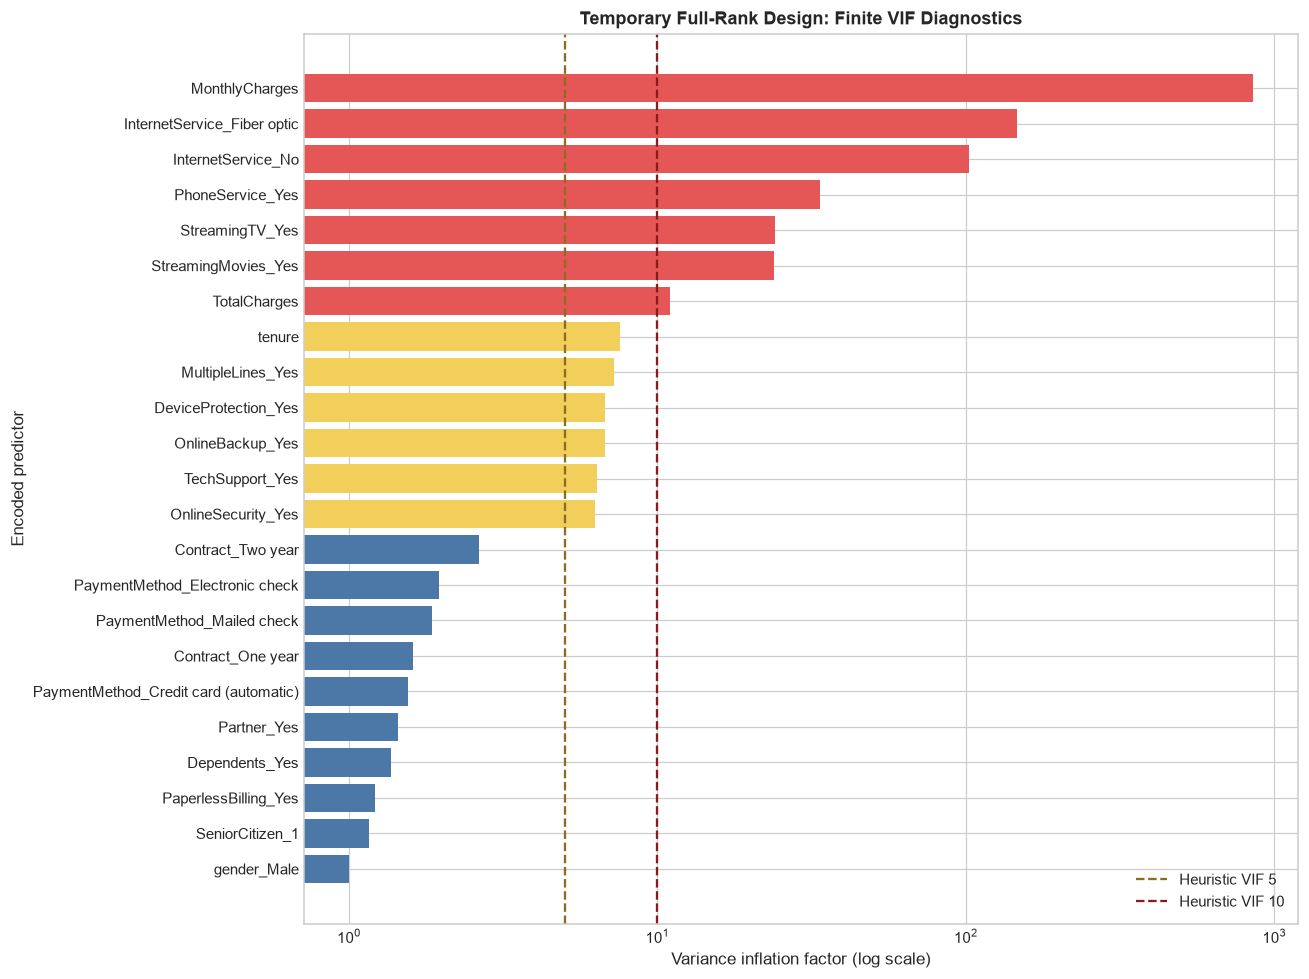

In [9]:
# ruff: noqa: E501
plot_table = full_rank_vif.sort_values("vif", ascending=True)
fig, axis = plt.subplots(figsize=(12, 9))
colors = np.where(plot_table["vif"] >= 10, "#E45756", np.where(plot_table["vif"] >= 5, "#F2CF5B", "#4C78A8"))
axis.barh(plot_table["predictor"], plot_table["vif"], color=colors)
axis.axvline(5, color="#8C6D1F", linestyle="--", label="Heuristic VIF 5")
axis.axvline(10, color="#8B1A1A", linestyle="--", label="Heuristic VIF 10")
axis.set_xscale("log")
axis.set(title="Temporary Full-Rank Design: Finite VIF Diagnostics", xlabel="Variance inflation factor (log scale)", ylabel="Encoded predictor")
axis.legend()
fig.tight_layout()
plt.show()

## 9. Future feature-engineering and modelling experiments

- **Reference-category encoding:** preserve a documented reference and verify rank after the complete preprocessing pipeline, not feature by feature in isolation.
- **Structural service representation:** compare explicit availability indicators plus subscriber adoption indicators against raw status categories. The temporary representation above is one candidate, not a production decision.
- **Regularization:** L2 can stabilize distributed coefficients; L1 can select among redundant signals but may choose arbitrarily across correlated variables. Tune both only inside leakage-safe validation.
- **Tree-based models:** retaining correlated predictors may preserve predictive information because trees do not require matrix inversion. Compare performance, stability, and attribution rather than pruning from VIF alone.
- **Numerical redundancy:** compare models with tenure, MonthlyCharges, and TotalCharges combinations through cross-validation, including calibration and temporal/business stability when suitable data become available.

These are experiments. The goal for coefficient-facing models is stable, interpretable parameterization; the goal for prediction is generalization. The best choice can differ by model family and deployment use.

## 10. Interview questions with speakable answers

### 1. What is multicollinearity, and how does it affect regression models?

Multicollinearity means predictors contain overlapping linear information. Perfect collinearity makes coefficients non-identifiable; strong approximate collinearity inflates coefficient uncertainty and makes signs or magnitudes unstable. Fitted predictions can still remain good because the combined signal is preserved.

### 2. How is VIF calculated and interpreted?

I regress one predictor on all the others with an intercept, obtain $R^2$, and calculate $1/(1-R^2)$. VIF says how much that coefficient's variance is inflated under the specified design. Five and ten are screening heuristics; infinity indicates exact dependence.

### 3. Can multicollinearity exist without high pairwise correlations?

Yes. One predictor can be nearly reconstructed from a combination of several predictors even if no individual pair is extreme. VIF and matrix-rank diagnostics can detect that multivariable relationship.

### 4. Should high-VIF features always be removed?

No. I first determine whether the cause is structural encoding, a derived business quantity, or genuine redundant noise. Then I compare reparameterization, regularization, and retained-feature models using leakage-safe validation. Interpretability and predictive performance are separate criteria.

## 11. Assumptions and limitations

1. VIF diagnoses linear dependence in a specific encoded design; it is not a universal property of a raw feature.
2. Dummy-column VIF is reference-sensitive and is not equivalent to a whole-feature categorical test.
3. The condition number is scale-sensitive, so nonconstant predictors were standardized and an intercept retained. Its threshold is contextual rather than a formal hypothesis test.
4. Structural identities reflect current data semantics. Production preprocessing must handle unseen categories and schema changes explicitly.
5. The IBM dataset has an undocumented sampling mechanism and no time dimension; stability across populations or periods is untested.
6. No PCA, hypothesis test, simulation, outcome model, feature elimination, permanent transformation, or preprocessing artifact is introduced.

## 12. Numerical, integrity, and leakage verification

The final cell verifies known numerical results, exact identities, rank deficiency and its resolution, all fourteen prior notebook hashes, the development checksum, and development-only loading.

In [10]:
# ruff: noqa: E501
expected_numerical_vif = {"tenure": 5.883536, "MonthlyCharges": 3.204469, "TotalCharges": 9.581309}
observed_numerical_vif = numerical_vif.set_index("predictor")["vif"].to_dict()
for predictor, expected in expected_numerical_vif.items():
    assert np.isclose(observed_numerical_vif[predictor], expected, rtol=1e-6)
assert np.isclose(pearson_reference, 0.828980, atol=1e-6)
assert reference_diagnostics["rank"] == 24 and reference_diagnostics["columns_with_intercept"] == 31 and reference_diagnostics["rank_deficiency"] == 7
assert full_rank_diagnostics["rank"] == full_rank_diagnostics["columns_with_intercept"] == 24
assert np.isclose(full_rank_diagnostics["condition_number"], 81.0719506, rtol=1e-6)
expected_exact_columns = {"PhoneService_Yes", "MultipleLines_No phone service", "InternetService_No", *[f"{addon}_No internet service" for addon in internet_addons]}
assert set(exact_dependency_vif["predictor"]) == expected_exact_columns
assert np.isinf(exact_dependency_vif["vif"]).all() and (exact_dependency_vif["tolerance"] == 0).all()
assert np.isfinite(full_rank_vif["vif"]).all() and (full_rank_vif["vif"] >= 1).all()
assert mixed_design.shape == (5_634, 30) and full_rank_design.shape == (5_634, 23)
assert identifier_column not in mixed_design and target_column not in mixed_design

expected_previous_hashes = {
    "01_exploratory_data_analysis.ipynb": "970288d8018d13770f972835b4ecc86fe7857e28c0b7447b104fa5b3edcf662b",
    "02_univariate_analysis.ipynb": "0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8edef76e26d61b851de4a",
    "03_bivariate_analysis.ipynb": "1ec80ddc2eb412b604841a20afa78e5199903ff00206f4e291a48a16d655d495",
    "04_multivariate_analysis.ipynb": "4bc0c85cdc2f8314b4d68ef1954e7b4c03b44902137b0ff01afbe3d596573331",
    "05_correlation_association_analysis.ipynb": "e787e951b3443c6052d960b384d5418c7c13e2e846c6d7e3a15f7895cd7faa13",
    "06_outlier_anomaly_analysis.ipynb": "f75450ecf0576bd49f35e864f2c5b8f389ac020b35ece57da2f74d9eb3e1ef4b",
    "07_customer_segmentation_business_analysis.ipynb": "1dee5509dc803187d99bb61af9d2eefc272f8a83c9d1014409f35834ca35cf6d",
    "08_statistical_foundations.ipynb": "11578c2e7cfa07a3fb826601d7afb356c224443d6547f7dc93725b45ac6653f2",
    "09_confidence_interval_analysis.ipynb": "50bf2497adec4d4e5d09502b0849420c9e53d5383615152f51fbc71629fb61c3",
    "10_distribution_diagnostics.ipynb": "38341766a6a26f1c7ba03c521500d15eef0038efd9e01d7b6bf7468de0dd1b58",
    "11_numerical_hypothesis_testing.ipynb": "fe98c6d2591d9f87dd256ae9a37a32004e194297f8dc01ce44abc6bff6501662",
    "12_categorical_hypothesis_testing.ipynb": "4d6cd50439617c88f1f0452961c56d0069877fa3352436bccc2aa35fa3f53389",
    "13_multiple_group_comparisons.ipynb": "1b2deba08ddcc68f3e2d6945aa657305ec04c6bae59b7c1c05912f026a18cf77",
    "14_effect_size_multiple_testing.ipynb": "a73bdd8cf7a221da928bda42a9f029971c141cf517daa0d0e8f89b610ef997d0",
}
observed_previous_hashes = {name: hashlib.sha256((PROJECT_ROOT / "notebooks" / name).read_bytes()).hexdigest() for name in expected_previous_hashes}
source_sha256_after = hashlib.sha256(development_path.read_bytes()).hexdigest()

assert observed_previous_hashes == expected_previous_hashes
assert source_sha256_before == source_sha256_after == "28d12b92122ab94a8172be83e2bcf7e93b128a1bf3633c2b48075c426864da13"
assert development_path != (PROJECT_ROOT / config["data"]["test_path"]).resolve()
assert development_path != (PROJECT_ROOT / config["data"]["validated_path"]).resolve()
assert random_state == 42

print("All VIF, rank, structural-dependency, integrity, and leakage checks passed.")
print("Loaded data source:", development_path.relative_to(PROJECT_ROOT))
print("Held-out test and complete validated datasets were not accessed.")
display(pd.DataFrame({"expected_sha256": expected_previous_hashes, "observed_sha256": observed_previous_hashes}))

All VIF, rank, structural-dependency, integrity, and leakage checks passed.
Loaded data source: data/processed/development.parquet
Held-out test and complete validated datasets were not accessed.


,expected_sha256,observed_sha256
01_exploratory_data_analysis.ipynb,970288d8018d13770f972835b4ecc86fe7857e28c0b744...,970288d8018d13770f972835b4ecc86fe7857e28c0b744...
02_univariate_analysis.ipynb,0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8ed...,0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8ed...
03_bivariate_analysis.ipynb,1ec80ddc2eb412b604841a20afa78e5199903ff00206f4...,1ec80ddc2eb412b604841a20afa78e5199903ff00206f4...
04_multivariate_analysis.ipynb,4bc0c85cdc2f8314b4d68ef1954e7b4c03b44902137b0f...,4bc0c85cdc2f8314b4d68ef1954e7b4c03b44902137b0f...
05_correlation_association_analysis.ipynb,e787e951b3443c6052d960b384d5418c7c13e2e846c6d7...,e787e951b3443c6052d960b384d5418c7c13e2e846c6d7...
06_outlier_anomaly_analysis.ipynb,f75450ecf0576bd49f35e864f2c5b8f389ac020b35ece5...,f75450ecf0576bd49f35e864f2c5b8f389ac020b35ece5...
07_customer_segmentation_business_analysis.ipynb,1dee5509dc803187d99bb61af9d2eefc272f8a83c9d101...,1dee5509dc803187d99bb61af9d2eefc272f8a83c9d101...
08_statistical_foundations.ipynb,11578c2e7cfa07a3fb826601d7afb356c224443d6547f7...,11578c2e7cfa07a3fb826601d7afb356c224443d6547f7...
09_confidence_interval_analysis.ipynb,50bf2497adec4d4e5d09502b0849420c9e53d538361515...,50bf2497adec4d4e5d09502b0849420c9e53d538361515...
10_distribution_diagnostics.ipynb,38341766a6a26f1c7ba03c521500d15eef0038efd9e01d...,38341766a6a26f1c7ba03c521500d15eef0038efd9e01d...
